<a href="https://colab.research.google.com/github/Ivanmaulana19/PCD5-6/blob/main/PCD_5_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving iqbal.jpg to iqbal (1).jpg


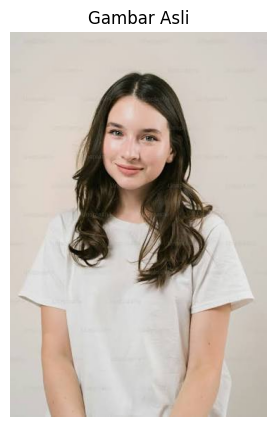

In [ ]:
import imageio.v3 as img
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# Upload gambar dari laptop (hanya perlu sekali di sini)
uploaded = files.upload()
filename = next(iter(uploaded))
image = img.imread(filename)

# Menampilkan gambar asli
plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.title("Gambar Asli")
plt.axis("off")
plt.show()

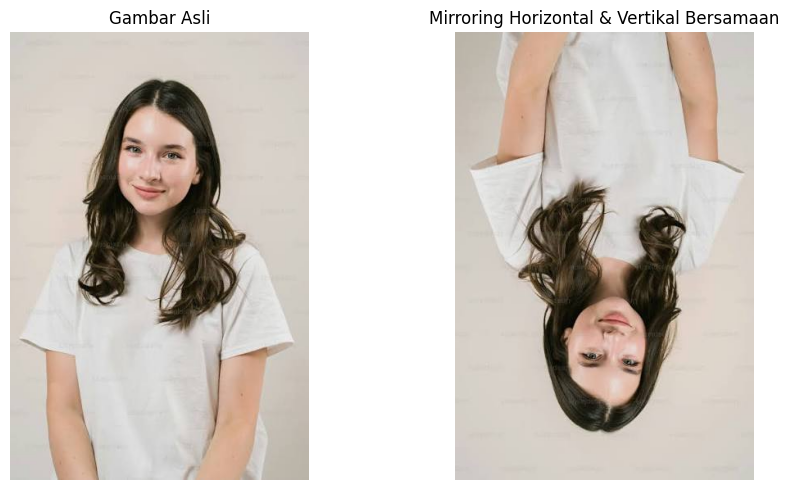

In [ ]:
height, width = image.shape[:2]
both_mirror = np.zeros_like(image)

for y in range(height):
    for x in range(width):
        both_mirror[y, x] = image[height - 1 - y, width - 1 - x]

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Gambar Asli")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(both_mirror)
plt.title("Mirroring Horizontal & Vertikal Bersamaan")
plt.axis("off")
plt.tight_layout()
plt.show()

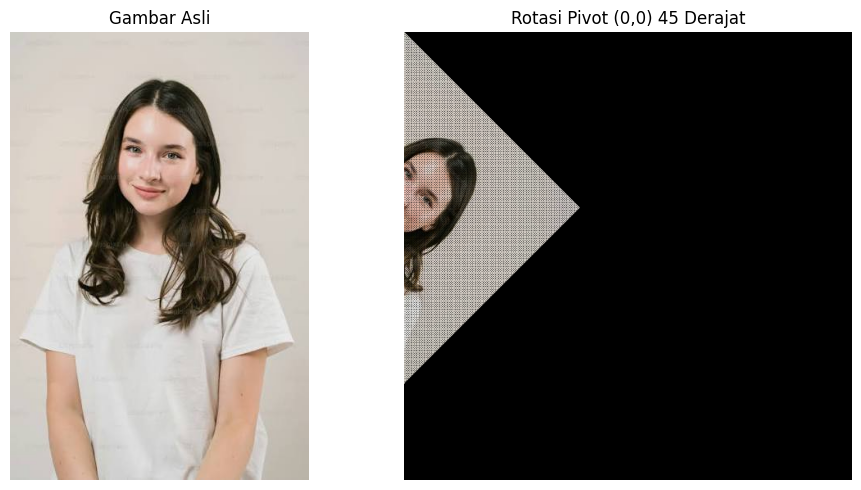

In [ ]:
def rotateImagePivot00(img_input, degree):
    radian_deg = np.radians(degree)
    cos_deg, sin_deg = np.cos(radian_deg), np.sin(radian_deg)

    h, w = img_input.shape[:2]
    max_dim = int(np.sqrt(h**2 + w**2))
    outputImage = np.zeros((max_dim, max_dim, 3), dtype=img_input.dtype)

    for y in range(h):
        for x in range(w):
            newX = int(cos_deg * x - sin_deg * y)
            newY = int(sin_deg * x + cos_deg * y)

            if 0 <= newX < max_dim and 0 <= newY < max_dim:
                outputImage[newY, newX] = img_input[y, x]

    return outputImage

rotated_image = rotateImagePivot00(image, 45)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Gambar Asli")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(rotated_image)
plt.title("Rotasi Pivot (0,0) 45 Derajat")
plt.axis("off")
plt.tight_layout()
plt.show()

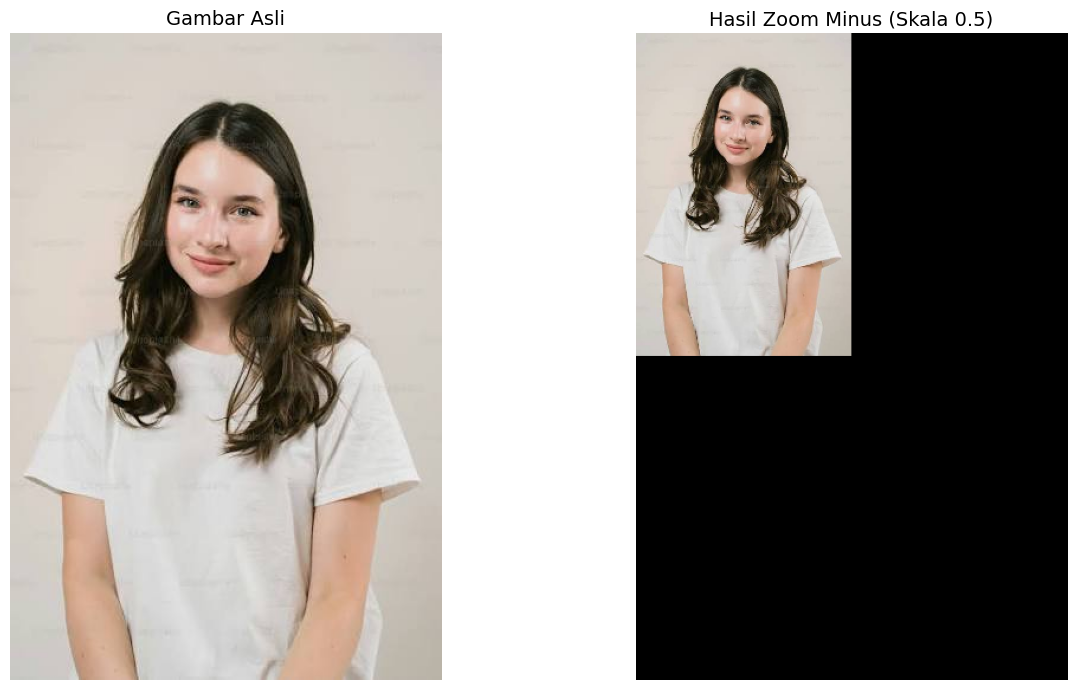

In [ ]:
# Fungsi Zoom Minus dengan menempatkan hasil perkecilan di atas canvas hitam sebesar gambar asli
def zoomMinus(img_input, factor):
    h, w = img_input.shape[:2]
    new_height = int(h * factor)
    new_width = int(w * factor)

    # Membuat canvas kosong (hitam) berukuran sama dengan gambar asli
    imgZoom = np.zeros_like(img_input)

    for y in range(new_height):
        for x in range(new_width):
            ori_y = int(y / factor)
            ori_x = int(x / factor)

            ori_y = min(ori_y, h - 1)
            ori_x = min(ori_x, width if 'width' in locals() else w - 1)

            imgZoom[y, x] = img_input[ori_y, ori_x]

    return imgZoom

# Mengatur skala perkecilan (misal 0.5 atau 0.6)
skala = 0.5
imgZoomMinus = zoomMinus(image, skala)

# Menampilkan gambar dengan ukuran figure yang lebih besar
plt.figure(figsize=(14, 7))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Gambar Asli", fontsize=14)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(imgZoomMinus)
plt.title(f"Hasil Zoom Minus (Skala {skala})", fontsize=14)
plt.axis("off")

plt.tight_layout()
plt.show()